### Setup

In [1]:
import sys
import os

!nvcc --version
!which nvcc

nvcc: NVIDIA (R) Cuda compiler driver
Copyright (c) 2005-2023 NVIDIA Corporation
Built on Tue_Feb__7_19:32:13_PST_2023
Cuda compilation tools, release 12.1, V12.1.66
Build cuda_12.1.r12.1/compiler.32415258_0
/usr/local/cuda-12.1/bin/nvcc


In [ ]:
%%capture
!{sys.executable} -m pip install bitsandbytes
!{sys.executable} -m pip install -U -q "unsloth[colab-new] @ git+https://github.com/unslothai/unsloth.git"
!{sys.executable} -m pip install -U -q --no-deps "xformers<0.0.26" trl peft accelerate
!{sys.executable} -m pip install flash-attn --no-build-isolation
#!{sys.executable} -m spacy download en_core_web_sm
!{sys.executable} -m pip install --pre -U xformers --index-url https://download.pytorch.org/whl/cu121




  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Installing backend dependencies ... done
  Preparing metadata (pyproject.toml) ... done
Looking in indexes: https://download.pytorch.org/whl/cu121
  Using cached https://download.pytorch.org/whl/cu121/xformers-0.0.26.post1-cp310-cp310-manylinux2014_x86_64.whl (222.7 MB)
  Attempting uninstall: xformers
    Found existing installation: xformers 0.0.25.post1
    Uninstalling xformers-0.0.25.post1:
      Successfully uninstalled xformers-0.0.25.post1


In [ ]:
!{sys.executable} -m bitsandbytes
!{sys.executable} -m xformers.info

In [2]:
import re
import pandas as pd
import gc
import math
import numpy as np
from sklearn.metrics import (accuracy_score,
                             classification_report,
                             confusion_matrix,
                             ConfusionMatrixDisplay)
from sklearn.model_selection import train_test_split
from datasets import Dataset
import bitsandbytes as bnb
from unsloth import FastLanguageModel
import torch
from tqdm import tqdm
from trl import SFTTrainer
from transformers import TrainingArguments, pipeline



/home/lesi-nedo/miniforge3/envs/HLT/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


🦥 Unsloth: Will patch your computer to enable 2x faster free finetuning.


2024-05-23 02:28:44.854103: I tensorflow/core/util/port.cc:113] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
2024-05-23 02:28:44.878915: E external/local_xla/xla/stream_executor/cuda/cuda_dnn.cc:9261] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
2024-05-23 02:28:44.878950: E external/local_xla/xla/stream_executor/cuda/cuda_fft.cc:607] Unable to register cuFFT factory: Attempting to register factory for plugin cuFFT when one has already been registered
2024-05-23 02:28:44.880061: E external/local_xla/xla/stream_executor/cuda/cuda_blas.cc:1515] Unable to register cuBLAS factory: Attempting to register factory for plugin cuBLAS when one has already been registered
2024-05-23 02:28:44.884597: I tensorflow/core/platform/cpu_feature_guar

### Specifying the path or Downloading the required files

In [3]:
to_download = 0 #If you want to get from the internet the required files
try:
  from google.colab import drive
  drive.mount('/content/drive')
  dir = "/content/drive/MyDrive/HLT project/Project files/sentiment_annotated_with_texts.csv"
  txt_sent_sent = "/content/drive/MyDrive/HLT project/Project files/SentiWordNet_3.0.0.txt"
  txt_sent_vad = "/content/drive/MyDrive/HLT project/Project files/NRC-VAD-Lexicon.txt"

except ModuleNotFoundError:
  if not to_download:
    dir = "/home/lesi-nedo/Desktop/master/second-semester/HLT/project/sentiment_annotated_with_texts.csv"
    txt_sent_sent = "/home/lesi-nedo/Desktop/master/second-semester/HLT/project/SentiWordNet_3.0.0.txt"
    txt_sent_vad = "/home/lesi-nedo/Desktop/master/second-semester/HLT/project/NRC-VAD-Lexicon.txt"
  else:
    if not os. path. exists("sentiment_annotated_with_texts.csv?download=1"):
      !wget https://zenodo.org/records/7976208/files/sentiment_annotated_with_texts.csv?download=1
      dir = "sentiment_annotated_with_texts.csv?download=1"
    if not os. path. exists("SentiWordNet_3.0.0.txt"):
      !wget https://raw.githubusercontent.com/aesuli/SentiWordNet/master/data/SentiWordNet_3.0.0.txt
      txt_sent_sent = "SentiWordNet_3.0.0.txt"
    if not os. path. exists("NRC-VAD-Lexicon.txt"):
      !wget https://raw.githubusercontent.com/nchibana/moviearcs/master/NRC-VAD-Lexicon.txt
      txt_sent_vad = "NRC-VAD-Lexicon.txt"

### Loading the dataset and lowering the text

In [4]:
def norm_text(data):

  return data.lower()
with open(dir, 'r') as f:
  df1 = pd.read_csv(f, delimiter=',', quotechar='"')

df1 = df1.sample(frac=1, random_state=56).reset_index(drop=True)
df = df1[['true_sentiment', 'title']]
del df1
df['title'] = df['title'].map(norm_text)
len(df)

2291

In [ ]:
import gc
del model
gc.collect()
torch.cuda.empty_cache() # PyTorch thing
# from numba import cuda

# cuda.select_device(0) # choosing second GPU
# cuda.close()

### Spliting the dataset

In [5]:
X_train1 = list()
X_test1 = list()
X_eval = list()
test_perc = 0.20
train_perc = (1.0 - test_perc)

df = df.sample(frac=1).reset_index(drop=True)


sentiments = ["Positive", "Neutral", "Negative"]



for sent in sentiments:
  train, test = train_test_split(
      df[df['true_sentiment'] == sent],
      train_size=1.0 - test_perc,
      test_size=test_perc,
      random_state=42,
  )
  X_train1.append(train)
  X_test1.append(test)

X_train1 = pd.concat(X_train1).sample(frac=1, random_state=56)
X_test1 = pd.concat(X_test1).sample(frac=1, random_state=42)

X_train1, X_eval1 = train_test_split(X_train1, train_size=0.9, test_size=0.1)

X_train1 = X_train1.reset_index(drop=True)
X_eval1 = X_eval1.reset_index(drop=True)

X_train1[:5]


,true_sentiment,title
0,Positive,usdjpy price analysis 200dma prods bulls at th...
1,Negative,gbpusd flatlines below mid12400s downside pote...
2,Neutral,eurgbp may keep hovering around 08800 this wee...
3,Negative,eurusd price analysis snaps twoday winning str...
4,Positive,eurusd door open to a probable move to 10750 –...


### Loading the SentiWordNet lexicons, and extracting the scores.

In [6]:

senti_word = {}
regex = '0(\.\d+)?\s0(\.\d+)?\s([a-z_\-]+#\d+\s)+'
pattern = re.compile(regex)


with open(txt_sent_sent, "r") as f:
  t = f.read()
  for si in t.split("\n"):
    if len(si) > 0 and si[0] != '#':
      matched = pattern.search(si)
      if matched:
        val = matched.group(0).split('\t')
        scor = [float(val[0]), float(val[1])]
        wors = re.split('#\d+\s?', val[2])
        wors.pop(-1)
        for wr in wors:
          senti_word[wr] = scor

df_senti = pd.DataFrame(senti_word, index=["pos_score", "negative_score"])
df_senti[:5]

,able,unable,dorsal,abaxial,ventral,adaxial,acroscopic,basiscopic,abducting,abducent,...,take_fire,conflagrate,catch_fire,flame_up,blaze_up,luminesce,shade_off,cloud_up,run_dry,fog_up
pos_score,0.25,0.125,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.00,0.0,0.000
negative_score,0.00,0.250,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.25,0.0,0.125


### Loading the VAD lexicon scores

In [7]:


data = {}

with open(txt_sent_vad, "r") as f:
  t = f.read()
  for si in t.split('\n')[1:-1]:
    si_w = (si +'\t').split('\t')
    if si_w[0] != '':
      data[si_w[0]] = list(map(lambda fl: float(fl), si_w[1:-1]))
    else:
      pass

for w,v in data.items():
  if len(v) < 3:
    print(w)

df2 = pd.DataFrame(data, index=['valence', 'arousal', 'dominance'])
df2[:5]

,aaaaaaah,aaaah,aardvark,aback,abacus,abalone,abandon,abandoned,abandonment,abashed,...,zit,zodiac,zombie,zone,zoning,zoo,zoological,zoology,zoom,zucchini
valence,0.479,0.520,0.427,0.385,0.510,0.500,0.052,0.046,0.128,0.177,...,0.337,0.594,0.214,0.531,0.417,0.76,0.667,0.568,0.490,0.510
arousal,0.606,0.636,0.490,0.407,0.276,0.480,0.519,0.481,0.430,0.644,...,0.410,0.429,0.648,0.349,0.400,0.52,0.458,0.347,0.520,0.321
dominance,0.291,0.282,0.437,0.288,0.485,0.412,0.245,0.130,0.202,0.307,...,0.381,0.426,0.415,0.382,0.578,0.58,0.492,0.509,0.462,0.250


### Downloading the model

In [8]:

max_seq_length = 2048
dtype = None
load_in_4bit = True
if  os.path.exists(f"{os.getcwd()}/llama-3-8b-Instruct-bnb-4bit"):
  model_name = f"{os.getcwd()}/llama-3-8b-Instruct-bnb-4bit"
else:
  model_name = "unsloth/llama-3-8b-Instruct-bnb-4bit"



fourbit_model = [
    "unsloth/llama-3-8b-Instruct-bnb-4bit",
]
model, tokenizer = FastLanguageModel.from_pretrained(
    model_name = model_name,
    use_cache=False,
    max_seq_length = max_seq_length,
    dtype = dtype,
    load_in_4bit = load_in_4bit,
    attn_implementation="flash_attention_2"
)

==((====))==  Unsloth: Fast Llama patching release 2024.5
   \\   /|    GPU: NVIDIA GeForce RTX 4080 Laptop GPU. Max memory: 11.721 GB. Platform = Linux.
O^O/ \_/ \    Pytorch: 2.3.0+cu121. CUDA = 8.9. CUDA Toolkit = 12.1.
\        /    Bfloat16 = TRUE. Xformers = 0.0.26.post1. FA = True.
 "-____-"     Free Apache license: http://github.com/unslothai/unsloth


Special tokens have been added in the vocabulary, make sure the associated word embeddings are fine-tuned or trained.


### Specifying various values for the tokenizer



In [9]:
tokenizer.model_max_length = max_seq_length
tokenizer.pad_token = tokenizer.eos_token  # use unk rather than eos token to prevent endless generation
tokenizer.pad_token_id = tokenizer.convert_tokens_to_ids(tokenizer.pad_token)
tokenizer.padding_side = 'left'
tokenizer.truncation_side = "left"


### The predict function
It uses the Hugging Face pipeline to generate text. It extracts the infered label by regex.

In [10]:
def predict(X_test, model, tokenizer):
  sent_reg = ".?([P,p]ositive|[N,n]egative|[N,n]eutral)"

  y_pred = []
  for i in tqdm(range(len(X_test))):
    prompt = X_test.iloc[i]['title']
    pipe = pipeline(task="text-generation",
                    model=model,
                    tokenizer=tokenizer,
                    max_new_tokens=4,
                    temperature=0.514,
                    return_tensors="pt",
                    truncation=True
                    )

    result = pipe(prompt, pad_token_id=pipe.tokenizer.eos_token_id, return_full_text=False, do_sample=False)
    answer_match = re.findall(sent_reg, result[0]['generated_text'])
    if len(answer_match) == 1 or (len(answer_match) == 2 and answer_match[0] == answer_match[1]):
      answer = answer_match[0].lower()
      if "positive" in answer:
        y_pred.append("Positive")
      elif "negative" in answer:
        y_pred.append("Negative")
      elif "neutral" in answer:
        y_pred.append("Neutral")
      else:
        print(f"\nWeird match: {answer}")
        y_pred.append("Unclear")
    else:
      print(f"\nNot found: {result[0]}")
      y_pred.append("Unclear")
  return y_pred

### Evaluation function
It calculates the accuracy for each label, and the classification matrix

In [11]:
def evaluate(y_true, y_pred):
  labels = [sent.lower() for sent in sentiments]
  mapping = {sentiments[0]: 2, sentiments[1]: 1, "Unclear": 1, sentiments[2]: 0}
  labels_map = {0: sentiments[0], 1: sentiments[1], 2: sentiments[1]}

  def map_func(x):
    return mapping.get(x, 1)

  y_true = np.vectorize(map_func)(y_true)
  y_pred = np.vectorize(map_func)(y_pred)

  accuracy = accuracy_score(y_true=y_true, y_pred=y_pred)
  print(f"Accuracy: {accuracy:.3f}")

  unique_labels = set(y_true)

  for label in unique_labels:
    label_indeces = [i for i in range(len(y_true))
                      if y_true[i] == label]
    label_y_true = [y_true[i] for i in label_indeces]
    label_y_pred = [y_pred[i] for i in label_indeces]
    accuracy = accuracy_score(label_y_true, label_y_pred)
    print(f"Accuracy for label {labels_map[label]}: {accuracy:.3f}")

  class_report = classification_report(y_true=y_true, y_pred=y_pred)
  print("\nClassification Report:")
  print(class_report)

  conf_matrix = confusion_matrix(y_true=y_true, y_pred=y_pred, labels=[0,1,2])
  print("\nConfusion Matrix:")
  disp = ConfusionMatrixDisplay(confusion_matrix=conf_matrix, display_labels=sentiments)
  disp.plot()

### Prompt generating
It generates the prompt for the train, eval set (with label) and for the test

In [12]:

def get_sentiment_vad(text):
  text_split = text.split(" ")
  total_score = [0, 0, 0]
  added = 1
  for word in text_split:
    if word in df2:
      total_score[0] += df2[word]['valence']
      total_score[1] += df2[word]['arousal']
      total_score[2] += df2[word]['dominance']
      added += 1
  return np.array(total_score) / added

def get_sentiment(text):
  text_split = text.split(" ")
  total_score = [0, 0]
  added = 1
  for i,word in enumerate(text_split):
    if word in df_senti:
      added += 1
      total_score[0] += df_senti[word]['pos_score']
      total_score[1] += df_senti[word]['negative_score']
    if i > 1:
      if text_split[i-1] + "_" + word in df_senti:
        total_score[0] += df_senti[text_split[i-1] + "_"+word]["pos_score"]
        total_score[1] += df_senti[text_split[i-1] + "_"+word]["negative_score"]
        added += 1

  return np.array(total_score) / added


text="""You are a  sentiment analysis model, perform the sentiment analysis of the headline enclosed in the angle brackets.
These scores related to the  headline must be considered in the analysis: Valence score {:.4f}, Arousal score {:.4f}, Dominance score {:.4f}, Positive SentiWordNet score {:.4f} and Negative SentiWordNet score {:.4f}.
It is imperative to keep in mind the direct correlation between the words.
Headline: <{}>
The response must be:
\n or positive
\n or negative
\n or neutral.
\n\nThe correct option is""".strip()

def formatting_prompts_func(examples):
    all_words = set()
    score = get_sentiment(examples["title"])
    score_vad = get_sentiment_vad(examples["title"])


    return text.format( score_vad[0], score_vad[1], score_vad[2], score[0], score[1],  examples['title']) + " " +  f"{examples['true_sentiment'].lower()}"




def formatting_prompts_func_test(examples):

    all_words = set()


    score = get_sentiment(examples["title"])
    score_vad = get_sentiment_vad(examples["title"])


    return text.format( score_vad[0], score_vad[1], score_vad[2], score[0], score[1],  examples['title'])



torch.backends.cuda.enable_mem_efficient_sdp(False)
torch.backends.cuda.enable_flash_sdp(False)

X_train = pd.DataFrame(X_train1.apply(formatting_prompts_func, axis=1), columns=['title'])
X_eval = pd.DataFrame(X_eval1.apply(formatting_prompts_func, axis=1), columns=['title'])
y_true = X_test1.true_sentiment
X_test = pd.DataFrame(X_test1.apply(formatting_prompts_func_test, axis=1), columns=['title'])

train_data = Dataset.from_pandas(X_train)
eval_data = Dataset.from_pandas(X_eval)
len(train_data)

1648

In [13]:
X_eval[:1]['title'].to_numpy()

array(['You are a  sentiment analysis model, perform the sentiment analysis of the headline enclosed in the angle brackets.\nThese scores related to the  headline must be considered in the analysis: Valence score 0.4130, Arousal score 0.3127, Dominance score 0.4803, Positive SentiWordNet score 0.0000 and Negative SentiWordNet score 0.0000.\nIt is imperative to keep in mind the direct correlation between the words.\nHeadline: <audusd technical analysis>\nThe response must be:\n\n or positive\n\n or negative\n\n or neutral.\n\n\nThe correct option is neutral'],
      dtype=object)

### Zero-shot prediction on test set

In [15]:
FastLanguageModel.for_inference(model)
y_pred = predict(X_test, model, tokenizer)

100%|█████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 459/459 [02:02<00:00,  3.74it/s]


Accuracy: 0.647
Accuracy for label Positive: 0.458
Accuracy for label Neutral: 0.718
Accuracy for label Neutral: 0.747

Classification Report:
              precision    recall  f1-score   support

           0       0.88      0.46      0.60       142
           1       0.55      0.72      0.62       163
           2       0.67      0.75      0.71       154

    accuracy                           0.65       459
   macro avg       0.70      0.64      0.64       459
weighted avg       0.69      0.65      0.64       459


Confusion Matrix:


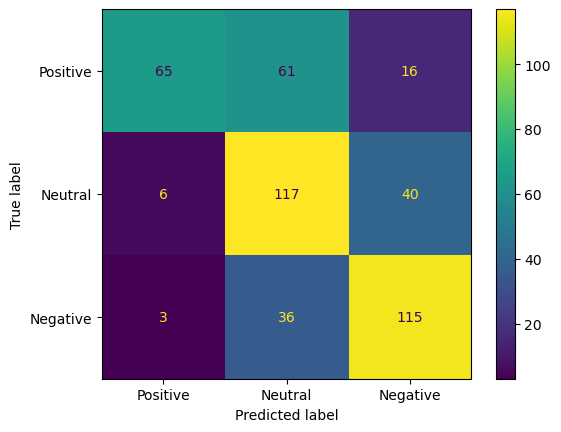

In [16]:
evaluate(y_true, y_pred)

### Geting the model with various setting

In [14]:
model = FastLanguageModel.get_peft_model(
    model,
    r = 32,
    target_modules = ["q_proj", "k_proj", "v_proj", "o_proj",
                    "gate_proj", "up_proj", "down_proj",],

    lora_alpha = 32,
    lora_dropout = 0.0001,
    bias = "none",
    use_gradient_checkpointing = True,
    random_state = 42,
    use_rslora = True,  # We support rank stabilized LoRA
    loftq_config = None, # And LoftQ
)

Unsloth: Dropout = 0 is supported for fast patching. You are using dropout = 0.0001.
Unsloth will patch all other layers, except LoRA matrices, causing a performance hit.
Unsloth 2024.5 patched 32 layers with 0 QKV layers, 0 O layers and 0 MLP layers.


In [15]:
training_config = {
    "do_eval": False,
    "do_train": True,
    "learning_rate": 2.0e-4,
    "adam_epsilon": 2.0e-4,
    "log_level": "info",
    "logging_steps": 10,
    "logging_strategy": "steps",
    "lr_scheduler_type": "linear",
    "num_train_epochs": 2,
    "max_steps": -1,
    "output_dir": "./checkpoint_dir",
    "overwrite_output_dir": True,
    "per_device_train_batch_size": 2,
    "gradient_accumulation_steps": 8,
    "save_steps": 200,
    "save_total_limit": 1,
    "gradient_checkpointing": True,
    "gradient_checkpointing_kwargs":{"use_reentrant": False},
    "warmup_ratio": 0.8,
    "fp16": not torch.cuda.is_bf16_supported(),
    "bf16": torch.cuda.is_bf16_supported(),
    "optim": "adamw_bnb_8bit",
    "weight_decay": 0.07,
    "seed": 42,
    "eval_strategy": 'steps',
    "group_by_length":True,
    }

trainer = SFTTrainer(
    model = model,
    tokenizer = tokenizer,
    train_dataset = train_data,
    eval_dataset = eval_data,
    dataset_text_field = "title",
    max_seq_length = max_seq_length,
    dataset_num_proc = 4,
    packing = False,
    args = TrainingArguments(
      **training_config
    ),
)
model.print_trainable_parameters()


Map (num_proc=4): 100%|███████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 184/184 [00:00<00:00, 221.00 examples/s]
Using auto half precision backend


trainable params: 83,886,080 || all params: 8,114,147,328 || trainable%: 1.0338


### Training configuration

### Fine-tuning

In [16]:
trainer_stats = trainer.train()

==((====))==  Unsloth - 2x faster free finetuning | Num GPUs = 1
   \\   /|    Num examples = 1,648 | Num Epochs = 2
O^O/ \_/ \    Batch size per device = 2 | Gradient Accumulation steps = 8
\        /    Total batch size = 16 | Total steps = 206
 "-____-"     Number of trainable parameters = 83,886,080


Step,Training Loss,Validation Loss
10,3.382700,3.026863
20,2.581900,2.044802
30,1.499600,0.873271
40,0.759400,0.630826
50,0.554200,0.611158
60,0.690100,0.583723
70,0.562600,0.559156
80,0.573100,0.551235
90,0.581400,0.543245
100,0.489500,0.546705


***** Running Evaluation *****
  Num examples = 184
  Batch size = 8
***** Running Evaluation *****
  Num examples = 184
  Batch size = 8
***** Running Evaluation *****
  Num examples = 184
  Batch size = 8
***** Running Evaluation *****
  Num examples = 184
  Batch size = 8
***** Running Evaluation *****
  Num examples = 184
  Batch size = 8
***** Running Evaluation *****
  Num examples = 184
  Batch size = 8
***** Running Evaluation *****
  Num examples = 184
  Batch size = 8
***** Running Evaluation *****
  Num examples = 184
  Batch size = 8
***** Running Evaluation *****
  Num examples = 184
  Batch size = 8
***** Running Evaluation *****
  Num examples = 184
  Batch size = 8
***** Running Evaluation *****
  Num examples = 184
  Batch size = 8
***** Running Evaluation *****
  Num examples = 184
  Batch size = 8
***** Running Evaluation *****
  Num examples = 184
  Batch size = 8
***** Running Evaluation *****
  Num examples = 184
  Batch size = 8
***** Running Evaluation *****
  N

### Print some metrics

In [17]:
metrics = trainer_stats.metrics
trainer.log_metrics("train", metrics)
trainer.save_metrics("train", metrics)
trainer.save_state()

***** train metrics *****
  epoch                    =        2.0
  total_flos               = 19938521GF
  train_loss               =     0.8315
  train_runtime            = 0:26:45.71
  train_samples_per_second =      2.053
  train_steps_per_second   =      0.128


### Prediction on fine-tuned model

In [18]:
FastLanguageModel.for_inference(model)
y_pred = predict(X_test, model, tokenizer)

100%|█████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 459/459 [02:10<00:00,  3.52it/s]


Accuracy: 0.802
Accuracy for label Positive: 0.845
Accuracy for label Neutral: 0.699
Accuracy for label Neutral: 0.870

Classification Report:
              precision    recall  f1-score   support

           0       0.82      0.85      0.83       142
           1       0.79      0.70      0.74       163
           2       0.80      0.87      0.83       154

    accuracy                           0.80       459
   macro avg       0.80      0.80      0.80       459
weighted avg       0.80      0.80      0.80       459


Confusion Matrix:


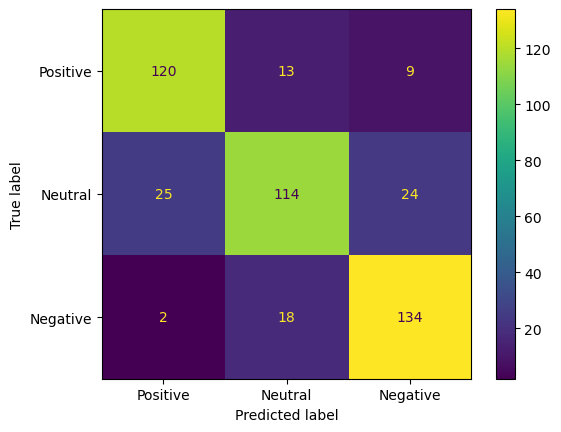

In [19]:
evaluate(y_true, y_pred) # 0.824

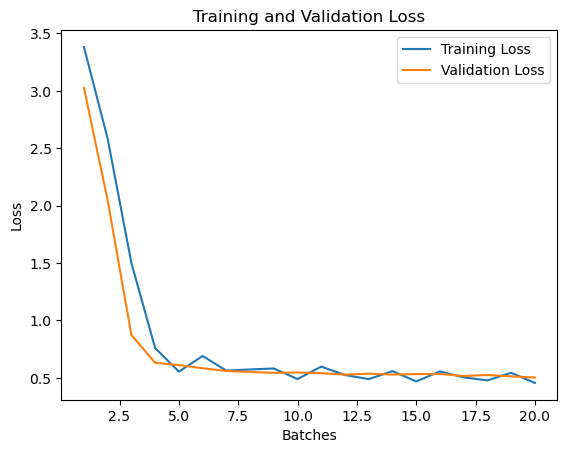

20

In [20]:
from matplotlib import pyplot as plt
train_loss = []
eval_loss = []
for elem in trainer.state.log_history:
    if 'loss' in elem.keys():
      train_loss.append(elem['loss'])
    if 'eval_loss' in elem.keys():
      eval_loss.append(elem['eval_loss'])
# # Generate a sequence of integers to represent the epoch numbers
epochs = range(1, 21)

# Plot and label the training and validation loss values
plt.plot(epochs, train_loss, label='Training Loss')
plt.plot(epochs, eval_loss, label='Validation Loss')

# Add in a title and axes labels
plt.title('Training and Validation Loss')
plt.xlabel('Batches')
plt.ylabel('Loss')

# Set the tick locations
# Display the plot
plt.legend(loc='best')
plt.show()
len(eval_loss)
# trainer.state.log_history

In [ ]:
model.save_pretrained_merged("llma3-model-fine-tuned", tokenizer)